# Customer Transaction Visualization & Dashboard

## Objective

To transform the findings from exploratory data analysis, transaction classification, and text analysis into meaningful visualizations.

This notebook focuses on identifying transaction patterns, understanding customer transaction behaviour, analysing financial activity, and presenting key insights through a consolidated dashboard.

In [2]:
# cell1 
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load the cleaned dataset
file_path = (
    Path.cwd().parent
    / "data"
    / "processed"
    / "cleaned_transactions.csv"
)

df = pd.read_csv(file_path)

# Display basic dataset information
print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset loaded successfully.
Dataset shape: (12043, 24)

Columns:
['status', 'card_present_flag', 'bpay_biller_code', 'account', 'currency', 'long_lat', 'txn_description', 'merchant_id', 'merchant_code', 'first_name', 'balance', 'date_original', 'gender', 'age', 'merchant_suburb', 'merchant_state', 'extraction', 'amount', 'transaction_id', 'country', 'customer_id', 'merchant_long_lat', 'movement', 'date']


In [3]:
# cell 2
# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Ensure amount is numeric
df["amount"] = pd.to_numeric(df["amount"], errors="coerce")

# Inspect important columns
print("Data types:")
print(df[["date", "amount", "movement"]].dtypes)

print("\nMissing values:")
print(df[["date", "amount", "movement"]].isnull().sum())

print("\nTransaction date range:")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

print("\nTransaction amount summary:")
print(df["amount"].describe())

Data types:
date        datetime64[us]
amount             float64
movement               str
dtype: object

Missing values:
date        0
amount      0
movement    0
dtype: int64

Transaction date range:
Start date: 2018-08-01 00:00:00
End date: 2018-10-31 00:00:00

Transaction amount summary:
count    12043.000000
mean       187.933588
std        592.599934
min          0.100000
25%         16.000000
50%         29.000000
75%         53.655000
max       8835.980000
Name: amount, dtype: float64


In [ ]:
# cell 3


CUSTOMER TRANSACTION OVERVIEW
-----------------------------------
Total Transactions: 12,043
Total Transaction Amount: 2,263,284.20
Average Transaction Amount: 187.93
Median Transaction Amount: 29.00
Unique Customers: 100

TRANSACTION MOVEMENT
-----------------------------------
Debit Transactions: 11,160
Credit Transactions: 883
Debit Percentage: 92.67%
Credit Percentage: 7.33%


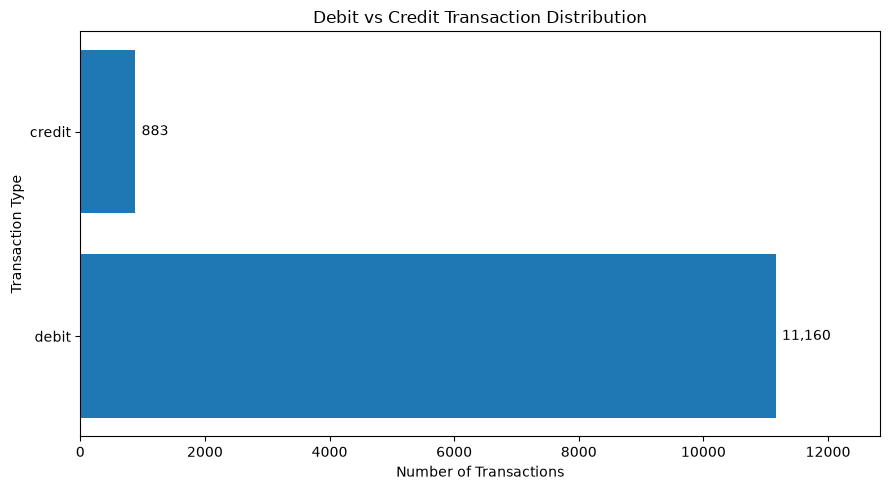

Chart saved successfully at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\transaction_type_distribution.png


In [ ]:
# cell 4

# Calculate transaction movement counts
movement_counts = (
    df["movement"]
    .value_counts()
    .reindex(["debit", "credit"])
)

# Locate the existing images folder in the project root
PROJECT_ROOT = Path.cwd().parent
IMAGE_DIR = PROJECT_ROOT / "images"

# Create the horizontal bar chart
plt.figure(figsize=(9, 5))

bars = plt.barh(
    movement_counts.index,
    movement_counts.values
)

# Add transaction counts beside each bar
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 100,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,}",
        va="center"
    )

plt.title("Debit vs Credit Transaction Distribution")
plt.xlabel("Number of Transactions")
plt.ylabel("Transaction Type")

plt.xlim(0, movement_counts.max() * 1.15)
plt.tight_layout()

# Save inside the existing images folder
image_path = IMAGE_DIR / "transaction_type_distribution.png"
plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved successfully at:", image_path)


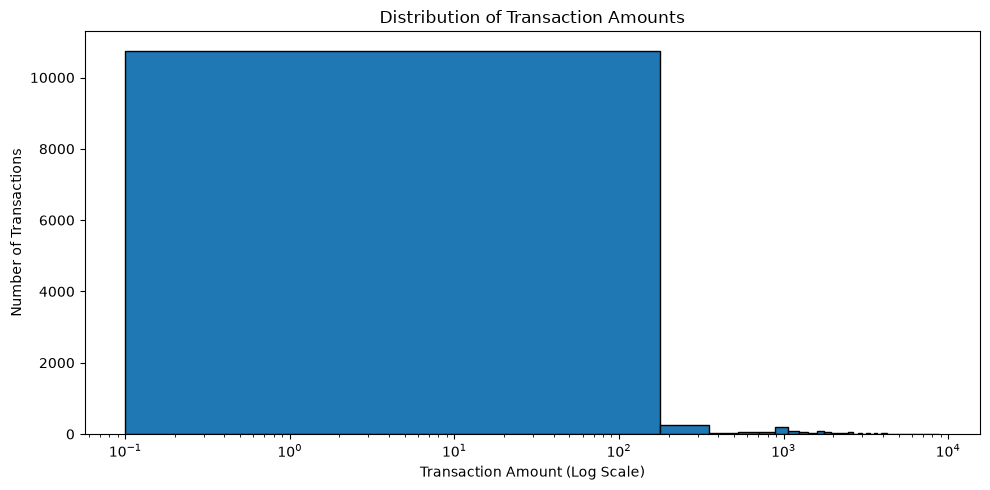

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\transaction_amount_distribution.png


In [9]:
# cell 5

# Plot transaction amount distribution
plt.figure(figsize=(10, 5))

plt.hist(
    df["amount"],
    bins=50,
    edgecolor="black"
)

plt.xscale("log")

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount (Log Scale)")
plt.ylabel("Number of Transactions")

plt.tight_layout()

# Save chart in the existing images folder
image_path = PROJECT_ROOT / "images" / "transaction_amount_distribution.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


### Observation

- Most transactions have relatively small amounts, concentrated towards the lower end of the distribution.
- The frequency of transactions decreases as the transaction amount increases.
- High-value transactions occur much less frequently than low-value transactions.
- The distribution is strongly right-skewed, indicating the presence of a small number of unusually large transactions.
- A logarithmic scale is used to make the distribution of transaction amounts easier to examine across a wide range of values.

**Insight:** Most customer transactions involve small amounts, while a relatively small number of high-value transactions contribute to the overall transaction amount.

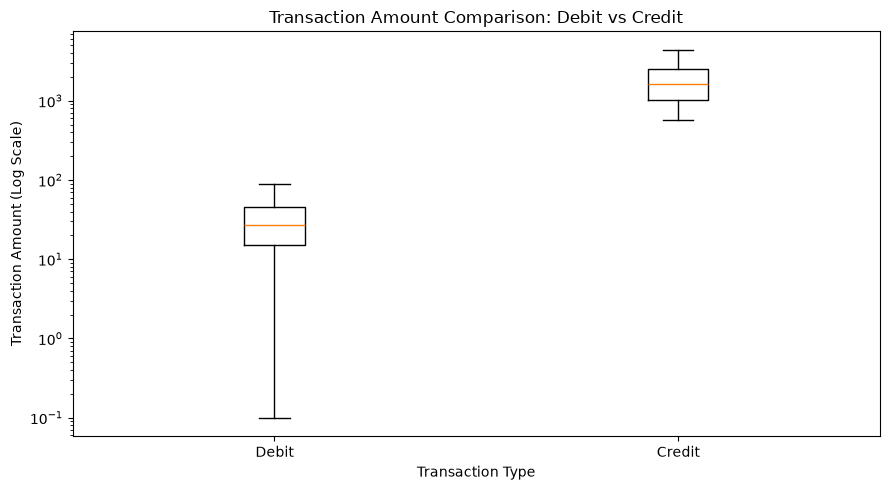

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\debit_credit_amount_comparison.png


In [11]:
# cell 6

# Create box plot
plt.figure(figsize=(9, 5))

plt.boxplot(
    [debit_amounts, credit_amounts],
    tick_labels=["Debit", "Credit"],
    showfliers=False
)

plt.yscale("log")

plt.title("Transaction Amount Comparison: Debit vs Credit")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Amount (Log Scale)")

plt.tight_layout()

# Save chart in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "debit_credit_amount_comparison.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


In [12]:
# cell 6.1 - verification cell 
# Calculate quartiles for both transaction types
quartile_summary = (
    df.groupby("movement")["amount"]
    .quantile([0.25, 0.50, 0.75])
    .unstack()
)

quartile_summary.columns = ["Q1 (25%)", "Median (50%)", "Q3 (75%)"]

print(quartile_summary)

          Q1 (25%)  Median (50%)  Q3 (75%)
movement                                  
credit     1013.67       1626.48   2538.68
debit        15.19         26.93     45.00


### Observation

- Credit transactions have significantly higher transaction amounts than debit transactions.
- The median credit transaction amount is 1,626.48, compared with 26.93 for debit transactions.
- The middle 50% of credit transactions range from 1,013.67 to 2,538.68, while debit transactions range from 15.19 to 45.00.
- Credit transactions show a wider spread in their central values, indicating greater variation in transaction amounts.
- Debit transactions are considerably more frequent, even though their individual transaction amounts are generally smaller.

**Insight:** Credit transactions generally involve larger amounts, whereas debit transactions occur more frequently and usually involve smaller amounts.

MONTHLY TRANSACTION SUMMARY


,transaction_count,total_amount
month,,
August 2018,3943,729935.52
September 2018,4013,730550.21
October 2018,4087,802798.47


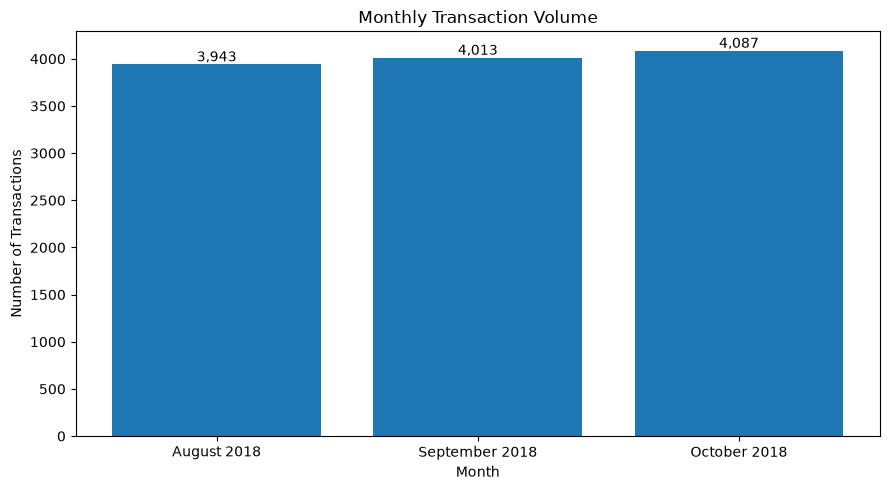

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\monthly_transaction_volume.png


In [13]:
# cell 7

# Extract month and year from transaction dates
df["month"] = df["date"].dt.strftime("%B %Y")

# Calculate monthly transaction metrics
monthly_summary = (
    df.groupby("month")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .reindex(["August 2018", "September 2018", "October 2018"])
)

print("MONTHLY TRANSACTION SUMMARY")
display(monthly_summary.round(2))

# Plot monthly transaction counts
plt.figure(figsize=(9, 5))

bars = plt.bar(
    monthly_summary.index,
    monthly_summary["transaction_count"]
)

# Add transaction counts above bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 30,
        f"{int(height):,}",
        ha="center"
    )

plt.title("Monthly Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")

plt.tight_layout()

# Save chart in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "monthly_transaction_volume.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


### Observation

- Transaction volume increased consistently across the three months, from 3,943 transactions in August to 4,087 in October.
- October recorded the highest transaction count, while August recorded the lowest.
- The total transaction amount also increased, reaching 802,798.47 in October.
- September showed only a slight increase in total transaction amount compared with August.
- Overall, the dataset indicates gradually increasing transaction activity during the observed period.

**Insight:** October experienced the highest transaction activity and total transaction amount among the three observed months.

DAILY TRANSACTION SUMMARY
Average daily transactions: 132.34
Highest daily transactions: 174
Lowest daily transactions: 89
Busiest day: 2018-09-28
Quietest day: 2018-10-30


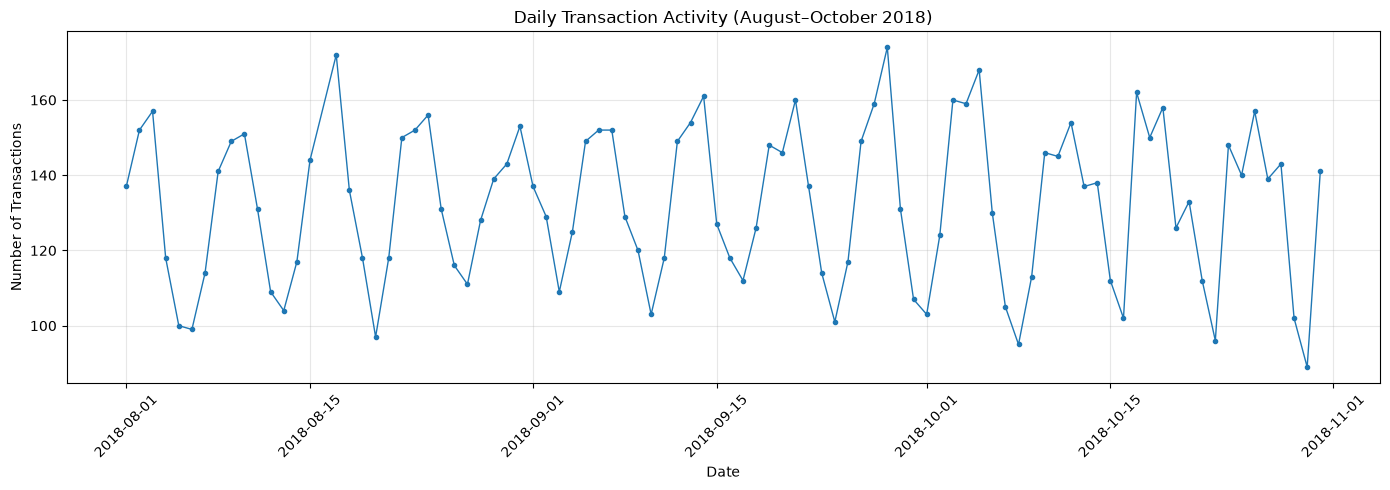

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\daily_transaction_activity.png


In [14]:
# cell 8

# Calculate daily transaction counts
daily_transactions = (
    df.groupby(df["date"].dt.date)
    .size()
)

# Identify the busiest and quietest days
print("DAILY TRANSACTION SUMMARY")
print("Average daily transactions:", round(daily_transactions.mean(), 2))
print("Highest daily transactions:", daily_transactions.max())
print("Lowest daily transactions:", daily_transactions.min())
print("Busiest day:", daily_transactions.idxmax())
print("Quietest day:", daily_transactions.idxmin())

# Plot daily transaction activity
plt.figure(figsize=(14, 5))

plt.plot(
    daily_transactions.index,
    daily_transactions.values,
    marker="o",
    markersize=3,
    linewidth=1
)

plt.title("Daily Transaction Activity (August–October 2018)")
plt.xlabel("Date")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()

# Save chart in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "daily_transaction_activity.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


TRANSACTION CATEGORY SUMMARY


,Transaction Description,Transaction Count
0,SALES-POS,3934
1,POS,3783
2,PAYMENT,2600
3,PAY/SALARY,883
4,INTER BANK,742
5,PHONE BANK,101


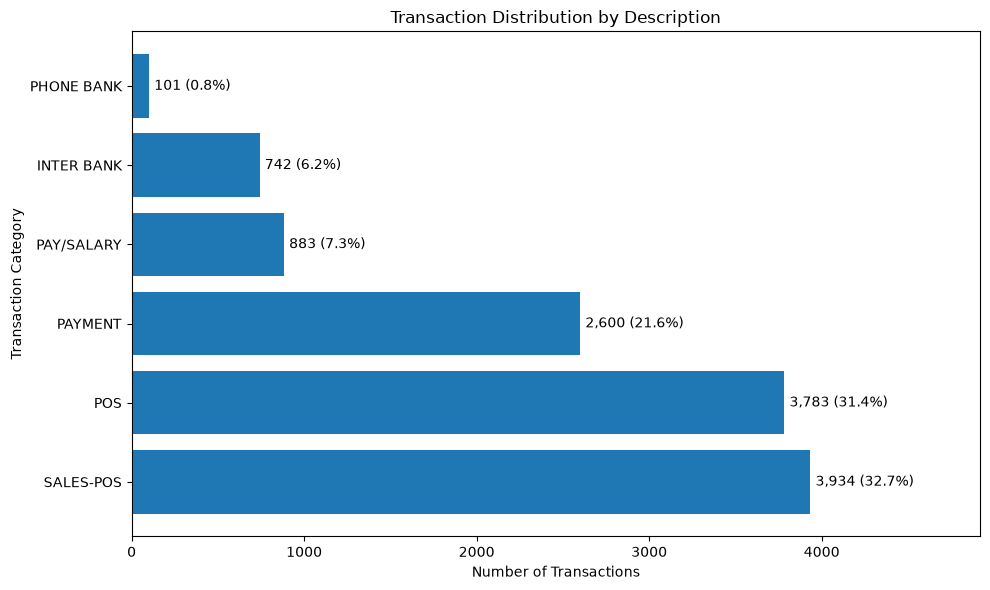

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\transaction_category_distribution.png


In [15]:
# cell 9

# Calculate transaction counts by description
description_counts = (
    df["txn_description"]
    .value_counts()
)

print("TRANSACTION CATEGORY SUMMARY")
display(
    description_counts
    .rename_axis("Transaction Description")
    .reset_index(name="Transaction Count")
)

# Calculate percentage contribution
description_percentage = (
    description_counts / len(df) * 100
)

# Create horizontal bar chart
plt.figure(figsize=(10, 6))

bars = plt.barh(
    description_counts.index,
    description_counts.values
)

# Display count and percentage beside each bar
for bar, percentage in zip(bars, description_percentage):
    width = bar.get_width()

    plt.text(
        width + 30,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,} ({percentage:.1f}%)",
        va="center"
    )

plt.title("Transaction Distribution by Description")
plt.xlabel("Number of Transactions")
plt.ylabel("Transaction Category")

plt.xlim(0, description_counts.max() * 1.25)
plt.tight_layout()

# Save in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "transaction_category_distribution.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


### Observation

- SALES-POS is the most frequent transaction category, accounting for 32.67% of all transactions.
- POS transactions contribute another 31.41%, making POS-related activity the dominant part of the dataset.
- Together, SALES-POS and POS account for approximately 64.08% of total transaction activity.
- PAYMENT represents 21.59% of transactions, making it the third-largest category.
- PHONE BANK is the least frequent category, contributing only 0.84%.

**Insight:** Customer transaction activity is heavily concentrated in POS-based transactions, while phone banking represents a very small proportion of recorded activity.


CUSTOMER TRANSACTION SUMMARY

Total unique customers: 100

Top 10 customers by total transaction amount:


,transaction_count,total_amount,average_amount
customer_id,,,
CUS-2738291516,80,45409.16,567.61
CUS-3142625864,163,42688.30,261.89
CUS-1816693151,78,40215.54,515.58
CUS-2155701614,101,37943.79,375.68
CUS-261674136,134,36786.13,274.52
CUS-883482547,178,36639.41,205.84
CUS-4142663097,174,36588.25,210.28
CUS-527400765,151,36543.61,242.01
CUS-1196156254,245,36050.72,147.15



Top 10 customers by transaction count:


,transaction_count,total_amount,average_amount
customer_id,,,
CUS-2487424745,578,26211.59,45.35
CUS-2142601169,303,23696.45,78.21
CUS-3026014945,292,29074.34,99.57
CUS-3378712515,260,22761.96,87.55
CUS-1614226872,259,19286.44,74.47
CUS-1196156254,245,36050.72,147.15
CUS-51506836,239,24100.75,100.84
CUS-2695611575,239,21479.97,89.87
CUS-860700529,233,18099.88,77.68


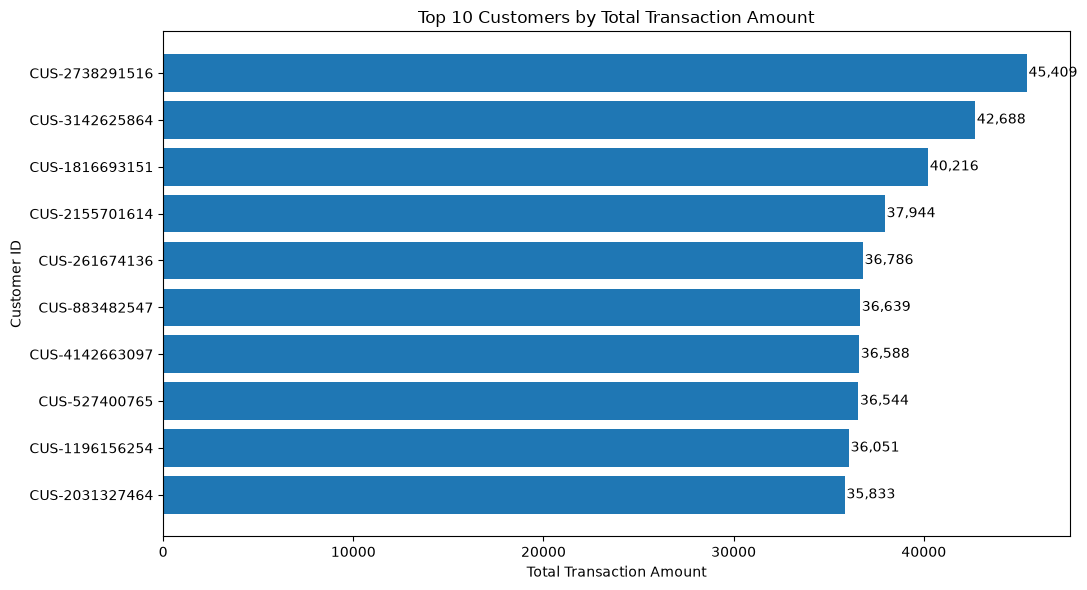

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\top_customers_by_transaction_amount.png


In [16]:
# cell10
# Calculate customer-level transaction metrics
customer_summary = (
    df.groupby("customer_id")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("total_amount", ascending=False)
)

print("CUSTOMER TRANSACTION SUMMARY")
print("\nTotal unique customers:", len(customer_summary))

print("\nTop 10 customers by total transaction amount:")
display(customer_summary.head(10).round(2))

print("\nTop 10 customers by transaction count:")
display(
    customer_summary
    .sort_values("transaction_count", ascending=False)
    .head(10)
    .round(2)
)

# Identify highest contributing customers
top_customers = customer_summary.head(10)

# Plot top 10 customers by total transaction amount
plt.figure(figsize=(11, 6))

bars = plt.barh(
    top_customers.index.astype(str),
    top_customers["total_amount"]
)

plt.gca().invert_yaxis()

for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 100,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center"
    )

plt.title("Top 10 Customers by Total Transaction Amount")
plt.xlabel("Total Transaction Amount")
plt.ylabel("Customer ID")

plt.tight_layout()

# Save chart in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "top_customers_by_transaction_amount.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


### Observation

- The dataset contains 100 unique customers.
- CUS-2738291516 recorded the highest total transaction amount of 45,409.16.
- CUS-2487424745 recorded the highest transaction frequency with 578 transactions.
- Customers with the highest transaction frequency are not necessarily those contributing the highest transaction amounts.
- CUS-1196156254 appears among the top 10 in both transaction value and transaction frequency.

**Insight:** Customer segmentation should consider both transaction frequency and total transaction value to distinguish highly active customers from high-value customers.

GEOGRAPHIC TRANSACTION SUMMARY
Transactions with merchant state: 7717
States represented: 8


,transaction_count,total_amount,percentage
merchant_state,,,
NSW,2169,102021.77,28.11
VIC,2131,87584.00,27.61
QLD,1556,53483.45,20.16
WA,1100,33992.06,14.25
SA,415,16776.57,5.38
NT,205,9168.89,2.66
ACT,73,4876.68,0.95
TAS,68,1962.93,0.88


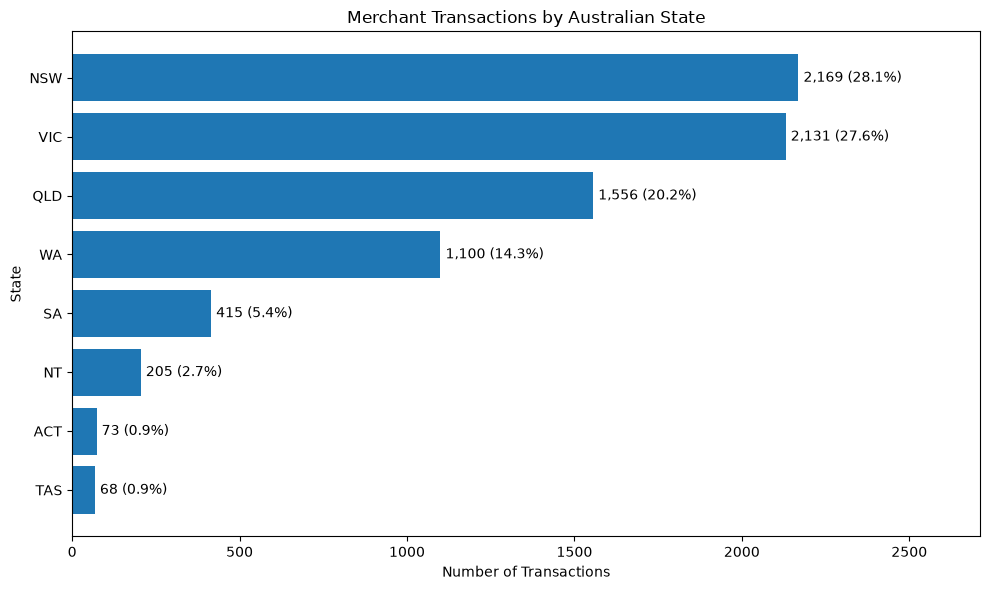

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\transactions_by_state.png


In [17]:
# cell 11
# Filter transactions with available merchant state information
state_df = df.dropna(subset=["merchant_state"]).copy()

# Calculate transaction counts by state
state_summary = (
    state_df.groupby("merchant_state")
    .agg(
        transaction_count=("transaction_id", "count"),
        total_amount=("amount", "sum")
    )
    .sort_values("transaction_count", ascending=False)
)

# Calculate percentage contribution
state_summary["percentage"] = (
    state_summary["transaction_count"]
    / state_summary["transaction_count"].sum() * 100
)

print("GEOGRAPHIC TRANSACTION SUMMARY")
print("Transactions with merchant state:", len(state_df))
print("States represented:", state_df["merchant_state"].nunique())

display(state_summary.round(2))

# Plot transaction counts by state
plt.figure(figsize=(10, 6))

bars = plt.barh(
    state_summary.index,
    state_summary["transaction_count"]
)

plt.gca().invert_yaxis()

for bar, percentage in zip(bars, state_summary["percentage"]):
    width = bar.get_width()

    plt.text(
        width + 15,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,} ({percentage:.1f}%)",
        va="center"
    )

plt.title("Merchant Transactions by Australian State")
plt.xlabel("Number of Transactions")
plt.ylabel("State")

plt.xlim(0, state_summary["transaction_count"].max() * 1.25)
plt.tight_layout()

# Save in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "transactions_by_state.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


### Observation

- NSW recorded the highest merchant transaction activity, contributing 28.11% of recorded transactions.
- VIC followed with 27.61%, while QLD and WA contributed 20.16% and 14.25%, respectively.
- The four leading states account for approximately 90.13% of transactions with available merchant-state information.
- TAS and ACT recorded the lowest transaction volumes.
- Geographic analysis is limited to 7,717 transactions because merchant-state information is available only for POS and SALES-POS categories.

**Insight:** Merchant transaction activity is geographically concentrated in NSW, VIC, QLD and WA, with NSW recording the highest volume.

CUSTOMER SEGMENTATION SUMMARY


,customer_count,total_transactions,total_amount,average_transaction_amount
customer_segment,,,,
Low Value,34,2672,492294.54,216.06
Medium Value,33,4673,705187.51,188.39
High Value,33,4698,1065802.15,282.55


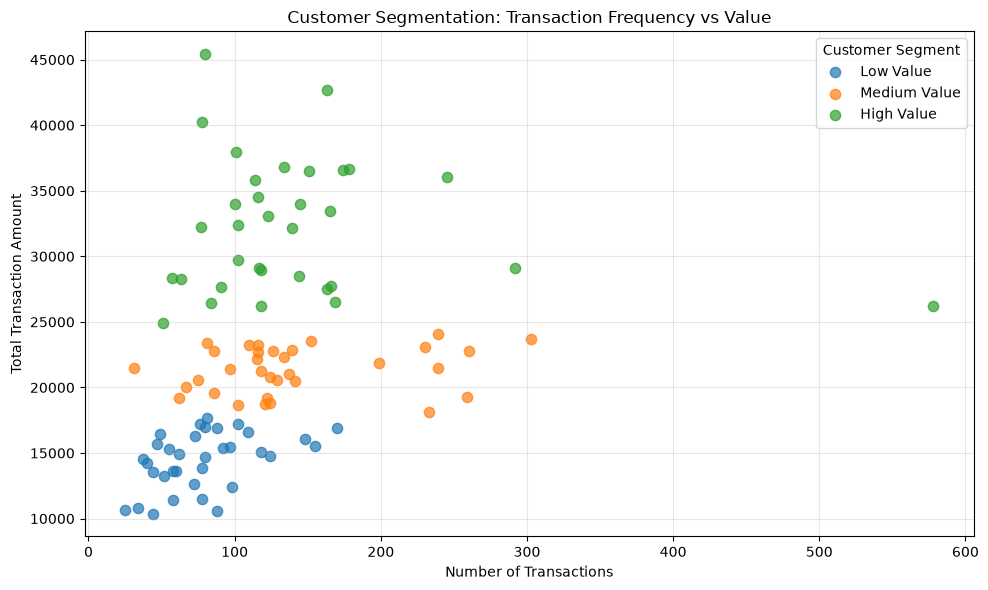

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\customer_value_segmentation.png


In [18]:
# cell 12
# Create customer segments based on total transaction amount
customer_summary["customer_segment"] = pd.qcut(
    customer_summary["total_amount"].rank(method="first"),
    q=3,
    labels=["Low Value", "Medium Value", "High Value"]
)

# Summarise customer segments
segment_summary = (
    customer_summary.groupby("customer_segment", observed=True)
    .agg(
        customer_count=("transaction_count", "count"),
        total_transactions=("transaction_count", "sum"),
        total_amount=("total_amount", "sum"),
        average_transaction_amount=("average_amount", "mean")
    )
)

print("CUSTOMER SEGMENTATION SUMMARY")
display(segment_summary.round(2))

# Compare customer transaction frequency and value
plt.figure(figsize=(10, 6))

for segment in ["Low Value", "Medium Value", "High Value"]:
    segment_data = customer_summary[
        customer_summary["customer_segment"] == segment
    ]

    plt.scatter(
        segment_data["transaction_count"],
        segment_data["total_amount"],
        label=segment,
        alpha=0.7,
        s=55
    )

plt.title("Customer Segmentation: Transaction Frequency vs Value")
plt.xlabel("Number of Transactions")
plt.ylabel("Total Transaction Amount")
plt.legend(title="Customer Segment")
plt.grid(alpha=0.3)

plt.tight_layout()

# Save in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "customer_value_segmentation.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)


CUSTOMER SEGMENT CONTRIBUTION


,Contribution Percentage
customer_segment,
Low Value,21.75
Medium Value,31.16
High Value,47.09


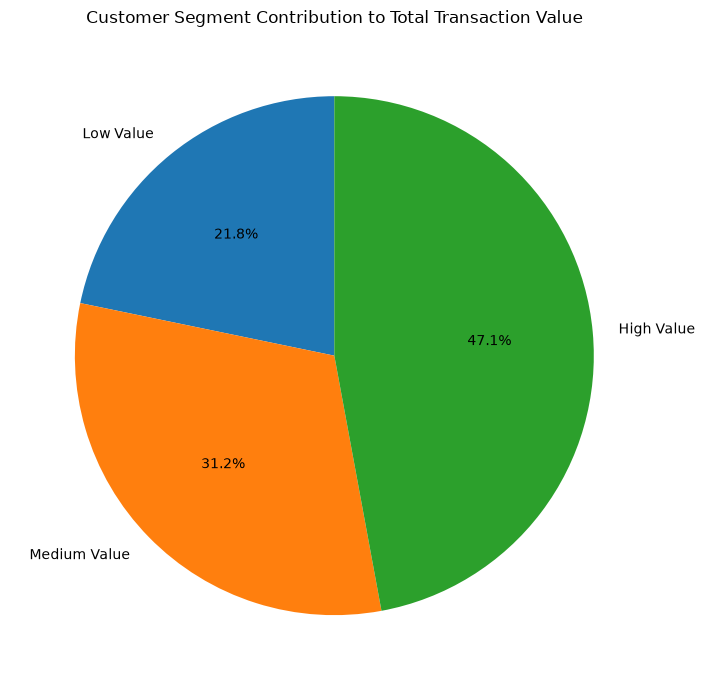

Chart saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\images\customer_segment_contribution.png


In [19]:
# cell 14

# Calculate percentage contribution by customer segment
segment_contribution = (
    segment_summary["total_amount"]
    / segment_summary["total_amount"].sum() * 100
)

print("CUSTOMER SEGMENT CONTRIBUTION")
display(
    segment_contribution
    .round(2)
    .rename("Contribution Percentage")
    .to_frame()
)

# Create pie chart
plt.figure(figsize=(8, 7))

plt.pie(
    segment_summary["total_amount"],
    labels=segment_summary.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Segment Contribution to Total Transaction Value")

plt.tight_layout()

# Save in the existing images folder
PROJECT_ROOT = Path.cwd().parent
image_path = PROJECT_ROOT / "images" / "customer_segment_contribution.png"

plt.savefig(image_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved at:", image_path)



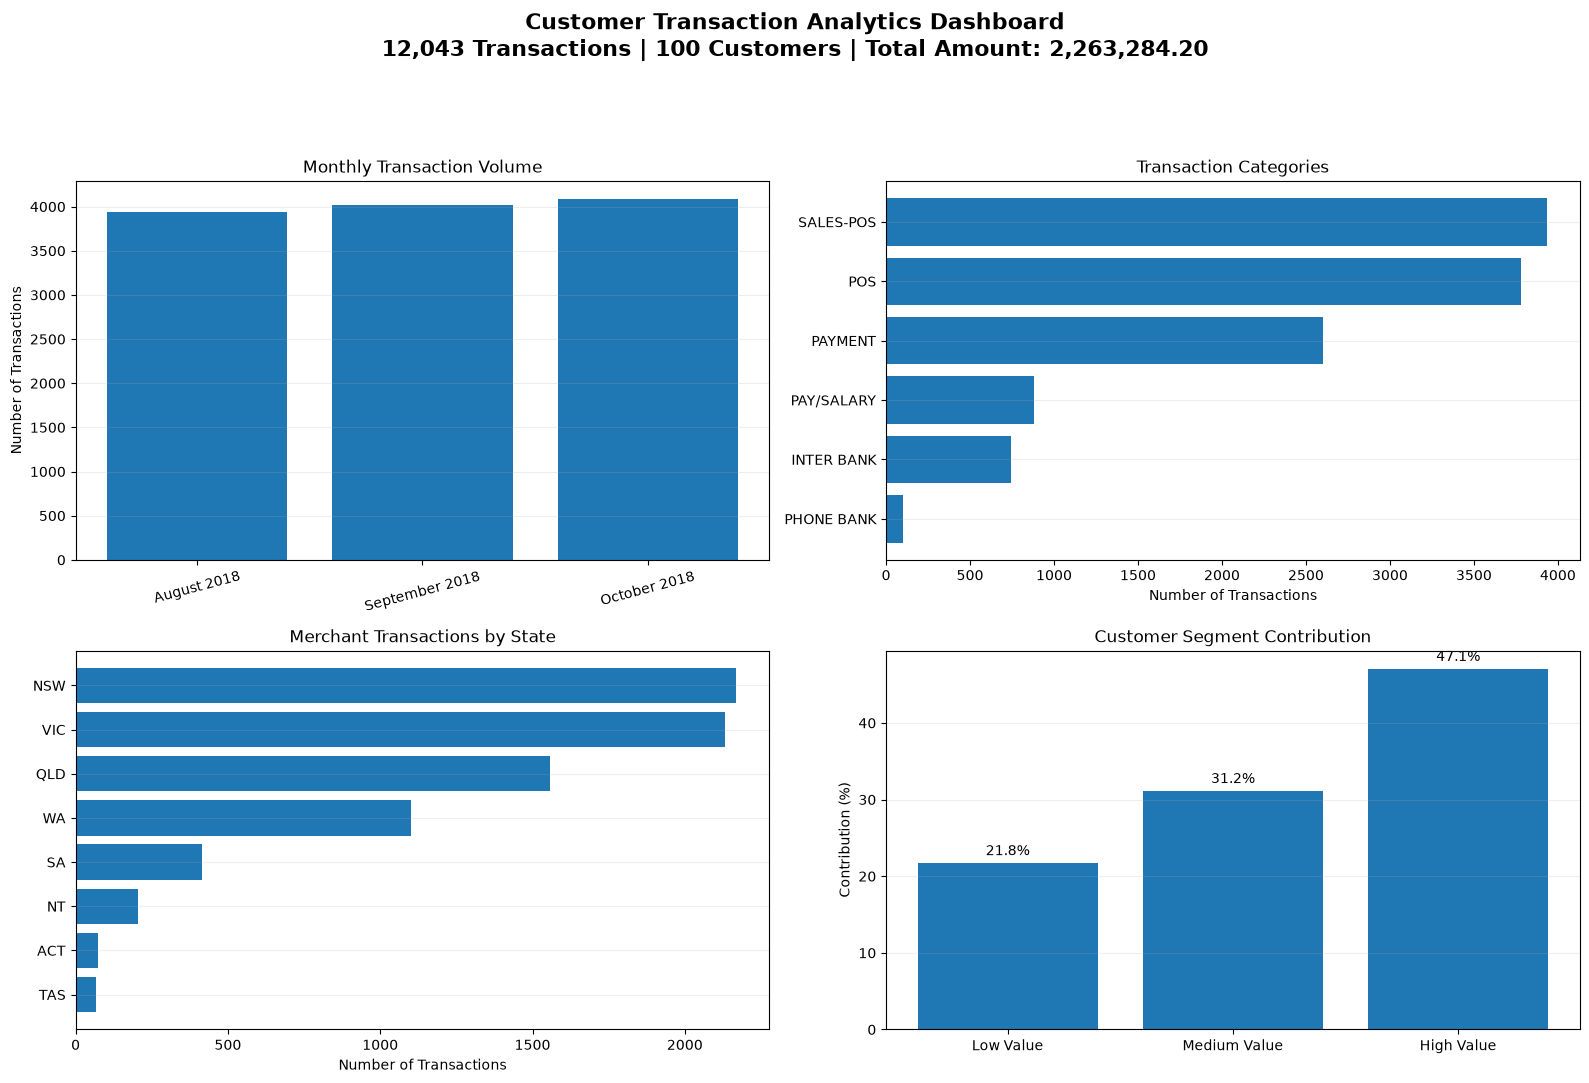

Dashboard saved at: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\dashboard\customer_transaction_dashboard.png
Old dashboard copy removed from images folder.


In [21]:
# cell 14

# Create a consolidated business dashboard

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Overall dashboard title and KPIs
fig.suptitle(
    f"Customer Transaction Analytics Dashboard\n"
    f"{total_transactions:,} Transactions | "
    f"{total_customers} Customers | "
    f"Total Amount: {total_amount:,.2f}",
    fontsize=16,
    fontweight="bold"
)

# 1. Monthly transaction volume
axes[0, 0].bar(
    monthly_summary.index,
    monthly_summary["transaction_count"]
)

axes[0, 0].set_title("Monthly Transaction Volume")
axes[0, 0].set_ylabel("Number of Transactions")
axes[0, 0].tick_params(axis="x", rotation=15)

# 2. Transaction category distribution
axes[0, 1].barh(
    description_counts.index,
    description_counts.values
)

axes[0, 1].set_title("Transaction Categories")
axes[0, 1].set_xlabel("Number of Transactions")
axes[0, 1].invert_yaxis()

# 3. Geographic distribution
axes[1, 0].barh(
    state_summary.index,
    state_summary["transaction_count"]
)

axes[1, 0].set_title("Merchant Transactions by State")
axes[1, 0].set_xlabel("Number of Transactions")
axes[1, 0].invert_yaxis()

# 4. Customer segment contribution
axes[1, 1].bar(
    segment_contribution.index.astype(str),
    segment_contribution.values
)

axes[1, 1].set_title("Customer Segment Contribution")
axes[1, 1].set_ylabel("Contribution (%)")

# Add percentage labels
for i, value in enumerate(segment_contribution.values):
    axes[1, 1].text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

# Improve dashboard layout
for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)

plt.tight_layout(rect=[0, 0, 1, 0.92])

# Save the consolidated dashboard in the existing dashboard folder
PROJECT_ROOT = Path.cwd().parent

DASHBOARD_DIR = PROJECT_ROOT / "dashboard"
IMAGE_DIR = PROJECT_ROOT / "images"

# Confirm that the existing dashboard folder is available
if not DASHBOARD_DIR.is_dir():
    raise FileNotFoundError("The dashboard folder does not exist.")

dashboard_path = DASHBOARD_DIR / "customer_transaction_dashboard.png"

# Save the dashboard in the dashboard folder
plt.savefig(dashboard_path, dpi=300, bbox_inches="tight")
plt.show()

# Remove the previous copy from images, if it exists
old_image_path = IMAGE_DIR / "customer_transaction_dashboard.png"

if old_image_path.exists():
    old_image_path.unlink()

print("Dashboard saved at:", dashboard_path)
print("Old dashboard copy removed from images folder.")

In [22]:
# cell 15
PROJECT_ROOT = Path.cwd().parent

dashboard_path = PROJECT_ROOT / "dashboard" / "customer_transaction_dashboard.png"
old_image_path = PROJECT_ROOT / "images" / "customer_transaction_dashboard.png"

print("DASHBOARD FILE")
print("Exists:", dashboard_path.exists())
print("Location:", dashboard_path)

print("\nOLD IMAGES COPY")
print("Still exists:", old_image_path.exists())

print("\nDASHBOARD DIRECTORY CONTENTS")
for file in sorted((PROJECT_ROOT / "dashboard").iterdir()):
    print(file.name)

print("\nIMAGES DIRECTORY FILE COUNT")
print(len(list((PROJECT_ROOT / "images").glob("*.png"))), "PNG files")

DASHBOARD FILE
Exists: True
Location: c:\Users\laksh\OneDrive\Desktop\projects\customer_transaction_prediction_analysis\dashboard\customer_transaction_dashboard.png

OLD IMAGES COPY
Still exists: False

DASHBOARD DIRECTORY CONTENTS
customer_transaction_dashboard.png

IMAGES DIRECTORY FILE COUNT
22 PNG files
